Paper Example 1: RNN solution with ordinary discretization
Exact x1=0.111111111, x2=0.444444444, f=0.666666667

m=   11 | x=(0.118441711, 0.422911690) | f=0.659795112 | dense viol=2.50e-03 | gap=1.13e-05 | iter= 50000 | runtime=3.267s
m=  101 | x=(0.112680771, 0.440699612) | f=0.666061155 | dense viol=2.09e-04 | gap=1.23e-04 | iter= 46180 | runtime=3.854s
m= 1001 | x=(0.112498088, 0.441051900) | f=0.666048075 | dense viol=2.12e-04 | gap=1.64e-04 | iter= 31360 | runtime=3.529s
m=10001 | x=(0.114489832, 0.437129904) | f=0.666109567 | dense viol=2.14e-04 | gap=9.73e-05 | iter= 12580 | runtime=3.869s

Results saved successfully!
Results : C:\Users\nsree\Desktop\linear-semi-infinite-program-with-gpu\results\rnn_lsip_results.csv
History : C:\Users\nsree\Desktop\linear-semi-infinite-program-with-gpu\results\rnn_lsip_history.csv

Final RNN report
    m       x1       x2  objective  objective_error  max_constraint_violation  iterations  runtime_sec  converged  primal_dual_gap
   11 0.118442 0.4

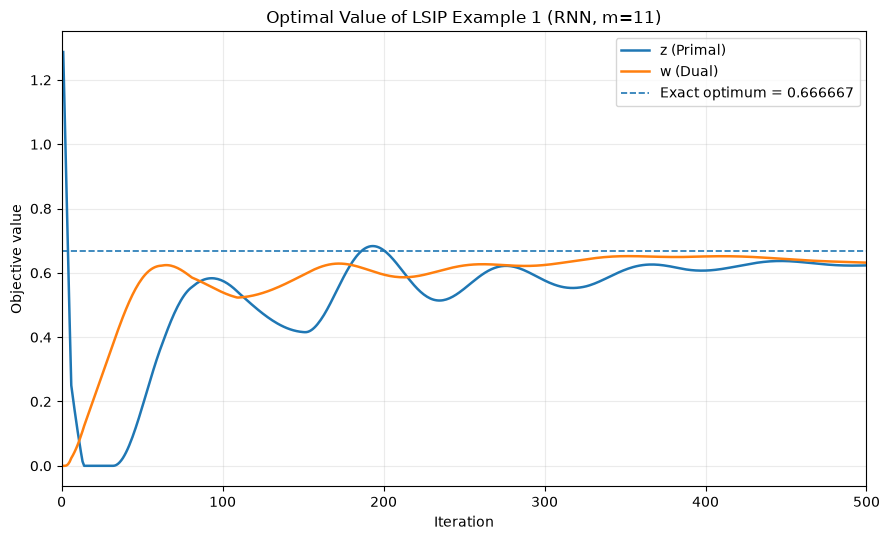

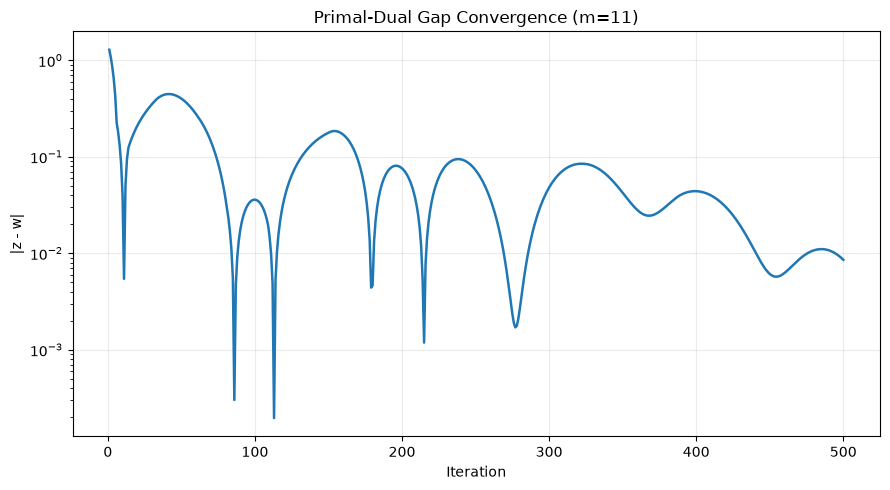


Plots saved successfully!
Paper-style z/w plot : C:\Users\nsree\Desktop\linear-semi-infinite-program-with-gpu\results\rnn_paper_style_z_w_m11.png
Primal-dual gap plot : C:\Users\nsree\Desktop\linear-semi-infinite-program-with-gpu\results\rnn_primal_dual_gap_m11.png


In [5]:
import time
import numpy as np
import pandas as pd
from scipy.optimize import linprog
import matplotlib.pyplot as plt

# ============================================================
# Paper-based RNN for Example 1 (Malek, Ahmadi, Alizamini, 2016)
#
# Original LSIP:
#   max z = -2*x1 - x2
#   s.t. -t*x1 + (t-1)*x2 <= t^2-t,  t in [0,1]
#        x >= 0
#
# We REPORT the positive minimization magnitude
#   f = 2*x1 + x2 = -z
# so the RNN output can be compared directly with the NOM CSV.
# ============================================================

SEED = 42
np.random.seed(SEED)

C = np.array([-2.0, -1.0], dtype=np.float64)  # paper's max objective C^T x
X_EXACT = np.array([1.0 / 9.0, 4.0 / 9.0], dtype=np.float64)
F_EXACT = 2.0 / 3.0


def build_constraints(m):
    """Ordinary discretization from the paper: m equally-spaced t values."""
    if m < 2:
        raise ValueError("m must be >= 2")
    t = np.linspace(0.0, 1.0, m, dtype=np.float64)
    A = np.column_stack((-t, t - 1.0))
    B = t**2 - t
    return t, A, B


def dense_constraint_check(x, n_dense=100_001):
    """Check the returned x against the ORIGINAL infinite constraint family."""
    x1, x2 = float(x[0]), float(x[1])
    t = np.linspace(0.0, 1.0, n_dense, dtype=np.float64)
    violation = (-t * x1 + (t - 1.0) * x2) - (t**2 - t)
    idx = int(np.argmax(violation))
    return float(max(0.0, violation[idx])), float(t[idx])


def solve_finite_lp(m):
    """Independent finite-LP benchmark for the same grid."""
    _, A, B = build_constraints(m)
    out = linprog(
        c=np.array([2.0, 1.0], dtype=np.float64),
        A_ub=A,
        b_ub=B,
        bounds=[(0.0, None), (0.0, None)],
        method="highs",
    )
    if not out.success:
        raise RuntimeError(f"linprog failed for m={m}: {out.message}")
    return out.x.astype(np.float64), float(out.fun)


def _paper_rnn_derivatives(x, y, A, B, eta1, eta2, active_eps=1e-12, max_active_iter=20):
    """
    Compute derivatives for paper equation (3):

        dx/ds = C - A^T (y + eta1 * dy/ds)
        dy/ds = A (x + eta2 * dx/ds) - B

    together with the paper's non-negativity projection (equations 4-5).

    Equation (3) is coupled/implicit. For a fixed active dual set J,
    it reduces to a 2x2 linear system:

      [I + eta1*eta2*A_J^T A_J] dx
         = C - A^T y - eta1*A_J^T(A_J x - B_J)

    Since this example has only two primal variables, solving that 2x2
    system is fast even when m=10001. The active set is updated until stable.
    """
    active = y > active_eps
    dx = np.zeros(2, dtype=np.float64)
    raw_dy = A @ x - B

    for _ in range(max_active_iter):
        if np.any(active):
            AJ = A[active]
            BJ = B[active]
            M = np.eye(2) + (eta1 * eta2) * (AJ.T @ AJ)
            rhs = C - A.T @ y - eta1 * (AJ.T @ (AJ @ x - BJ))
        else:
            M = np.eye(2)
            rhs = C - A.T @ y

        dx = np.linalg.solve(M, rhs)

        # Paper Eq. (4): if a primal state is at zero, disallow negative motion.
        dx = np.where((x > active_eps) | (dx > 0.0), dx, 0.0)

        raw_dy = A @ (x + eta2 * dx) - B

        # Paper Eq. (5): a zero dual state moves only if its residual is positive.
        new_active = (y > active_eps) | (raw_dy > 0.0)
        if np.array_equal(new_active, active):
            active = new_active
            break
        active = new_active

    dy = np.where(active, raw_dy, 0.0)
    return dx, dy


def _metrics(x, y, A, B):
    """KKT-style diagnostics for the discretized primal/dual pair."""
    primal_z = float(C @ x)             # negative, because C=[-2,-1]
    dual_w = float(B @ y)               # same sign convention as paper LP
    objective = -primal_z               # positive f=2*x1+x2 for NOM comparison
    dual_objective_mag = -dual_w

    primal_violation = float(max(0.0, np.max(A @ x - B)))
    dual_violation = float(max(0.0, np.max(C - A.T @ y)))
    primal_dual_gap = float(abs(primal_z - dual_w))
    kkt_merit = primal_violation + dual_violation + primal_dual_gap

    return {
        "objective": objective,
        "primal_z": primal_z,
        "dual_w": dual_w,
        "dual_objective_magnitude": dual_objective_mag,
        "grid_max_violation": primal_violation,
        "dual_max_violation": dual_violation,
        "primal_dual_gap": primal_dual_gap,
        "kkt_merit": kkt_merit,
    }


def solve_rnn(
    m,
    max_iterations=50_000,
    eta1=0.1,
    eta2=0.1,
    base_step=0.10,
    kkt_tol=5e-4,
    check_every=10,
    history_every=500,
    paper_history_iterations=500,
    verbose=False,
):
    """
    Numerically integrate the paper RNN dynamics.

    The paper specifies eta1/eta2 as learning rates but does not give numerical
    values or the ODE integrator settings for Example 1. We therefore use a
    documented, reproducible choice and scale the Euler step by ||A||_2 to keep
    the discretization stable as m grows.
    """
    _, A, B = build_constraints(m)

    # Positive initial primal state; zero dual state.
    x = np.array([0.5, 0.5], dtype=np.float64)
    y = np.zeros(m, dtype=np.float64)

    # Stable numerical integration across very different grid sizes.
    spectral_norm = float(np.linalg.norm(A, ord=2))
    step = base_step / max(1.0, spectral_norm)

    best = None
    history = []
    started = time.perf_counter()
    actual_iterations = 0

    for iteration in range(1, max_iterations + 1):
        dx, dy = _paper_rnn_derivatives(x, y, A, B, eta1, eta2)

        # Forward Euler integration + nonnegative state projection.
        x = np.maximum(0.0, x + step * dx)
        y = np.maximum(0.0, y + step * dy)
        actual_iterations = iteration

        if iteration % check_every == 0 or iteration == 1:
            met = _metrics(x, y, A, B)

            # Best state is chosen ONLY by KKT diagnostics, not by the known answer.
            if best is None or met["kkt_merit"] < best[0]:
                best = (met["kkt_merit"], iteration, x.copy(), y.copy(), met.copy())

            if verbose and (iteration % history_every == 0 or iteration == 1):
                print(
                    f"m={m:5d} iter={iteration:6d} "
                    f"x=({x[0]:.7f},{x[1]:.7f}) "
                    f"f={met['objective']:.7f} "
                    f"pviol={met['grid_max_violation']:.2e} "
                    f"dviol={met['dual_max_violation']:.2e} "
                    f"gap={met['primal_dual_gap']:.2e}"
                )

            if met["kkt_merit"] <= kkt_tol:
                break

        # Save every iteration during the first 500 steps so we can reproduce
        # the paper-style z/w convergence figure. After that, save sparsely.
        if iteration <= paper_history_iterations or iteration % history_every == 0:
            met_h = _metrics(x, y, A, B)
            history.append({
                "m": m,
                "iteration": iteration,
                "x1": float(x[0]),
                "x2": float(x[1]),

                # Paper-style positive objective magnitudes
                "z": abs(float(met_h["primal_z"])),
                "w": abs(float(met_h["dual_w"])),

                "objective": met_h["objective"],
                "grid_max_violation": met_h["grid_max_violation"],
                "dual_max_violation": met_h["dual_max_violation"],
                "primal_dual_gap": met_h["primal_dual_gap"],
                "kkt_merit": met_h["kkt_merit"],
            })

    elapsed = time.perf_counter() - started

    # Use the best KKT state seen during integration.
    _, best_iter, x_best, y_best, met = best
    dense_v, worst_t = dense_constraint_check(x_best)
    lp_x, lp_f = solve_finite_lp(m)

    result = {
        # Core schema matching NOM comparison needs
        "m": m,
        "method": "RNN-paper-Eq3",
        "x1": float(x_best[0]),
        "x2": float(x_best[1]),
        "objective": float(met["objective"]),
        "objective_error": abs(float(met["objective"]) - F_EXACT),
        "max_constraint_violation": dense_v,
        "iterations": int(best_iter),
        "runtime_sec": float(elapsed),
        "converged": bool(met["kkt_merit"] <= kkt_tol),

        # Extra diagnostics
        "grid_max_violation": float(met["grid_max_violation"]),
        "dense_max_violation": dense_v,
        "worst_t": worst_t,
        "dual_max_violation": float(met["dual_max_violation"]),
        "primal_dual_gap": float(met["primal_dual_gap"]),
        "kkt_merit": float(met["kkt_merit"]),
        "paper_primal_z": float(met["primal_z"]),
        "paper_dual_w": float(met["dual_w"]),
        "paper_z_magnitude": abs(float(met["primal_z"])),
        "paper_w_magnitude": abs(float(met["dual_w"])),
        "lp_x1": float(lp_x[0]),
        "lp_x2": float(lp_x[1]),
        "lp_objective": float(lp_f),
        "objective_error_vs_finite_lp": abs(float(met["objective"]) - lp_f),
        "x_error_vs_exact_lsip": float(np.linalg.norm(x_best - X_EXACT)),
        "eta1": float(eta1),
        "eta2": float(eta2),
        "integration_step": float(step),
        "max_iterations": int(max_iterations),
        "iterations_executed": int(actual_iterations),
    }

    return result, pd.DataFrame(history)


def plot_paper_style_convergence(history_df, m=11, max_iteration=500, save_path=None):
    """
    Reproduce the paper-style Figure 1 using the stored primal z and dual w
    objective magnitudes over the first 500 RNN iterations.
    """
    plot_df = history_df[
        (history_df["m"] == m) &
        (history_df["iteration"] <= max_iteration)
    ].copy()

    if plot_df.empty:
        raise ValueError(
            f"No history available for m={m} up to iteration {max_iteration}."
        )

    plt.figure(figsize=(9, 5.5))
    plt.plot(
        plot_df["iteration"],
        plot_df["z"],
        linewidth=1.8,
        label="z (Primal)"
    )
    plt.plot(
        plot_df["iteration"],
        plot_df["w"],
        linewidth=1.8,
        label="w (Dual)"
    )
    plt.axhline(
        F_EXACT,
        linestyle="--",
        linewidth=1.2,
        label=f"Exact optimum = {F_EXACT:.6f}"
    )

    plt.xlabel("Iteration")
    plt.ylabel("Objective value")
    plt.title(f"Optimal Value of LSIP Example 1 (RNN, m={m})")
    plt.xlim(0, max_iteration)
    plt.legend()
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()


def plot_primal_dual_gap(history_df, m=11, max_iteration=500, save_path=None):
    """Plot |z-w| to visualize primal-dual convergence."""
    plot_df = history_df[
        (history_df["m"] == m) &
        (history_df["iteration"] <= max_iteration)
    ].copy()

    if plot_df.empty:
        raise ValueError(
            f"No history available for m={m} up to iteration {max_iteration}."
        )

    plt.figure(figsize=(9, 5))
    plt.plot(
        plot_df["iteration"],
        plot_df["primal_dual_gap"],
        linewidth=1.8
    )
    plt.xlabel("Iteration")
    plt.ylabel("|z - w|")
    plt.title(f"Primal-Dual Gap Convergence (m={m})")
    plt.yscale("log")
    plt.grid(True, alpha=0.25)
    plt.tight_layout()

    if save_path is not None:
        plt.savefig(save_path, dpi=200, bbox_inches="tight")

    plt.show()


if __name__ == "__main__":
    grid_sizes = [11, 101, 1001, 10001]

    print("Paper Example 1: RNN solution with ordinary discretization")
    print(f"Exact x1={X_EXACT[0]:.9f}, x2={X_EXACT[1]:.9f}, f={F_EXACT:.9f}\n")

    results = []
    histories = []

    for m in grid_sizes:
        result, hist = solve_rnn(
            m=m,
            max_iterations=50_000,
            eta1=0.1,
            eta2=0.1,
            base_step=0.10,
            kkt_tol=5e-4,
            check_every=10,
            history_every=500,
            paper_history_iterations=500,
            verbose=False,
        )
        results.append(result)
        histories.append(hist)

        print(
            f"m={m:5d} | x=({result['x1']:.9f}, {result['x2']:.9f}) | "
            f"f={result['objective']:.9f} | "
            f"dense viol={result['dense_max_violation']:.2e} | "
            f"gap={result['primal_dual_gap']:.2e} | "
            f"iter={result['iterations']:6d} | "
            f"runtime={result['runtime_sec']:.3f}s"
        )

    results_df = pd.DataFrame(results)
    history_df = pd.concat(histories, ignore_index=True)
    # ============================================================
    # SAVE RESULTS - WINDOWS / LOCAL NOTEBOOK
    # ============================================================

    from pathlib import Path

    # Create a results folder beside your notebook/script
    output_dir = Path.cwd() / "results"
    output_dir.mkdir(parents=True, exist_ok=True)

    results_path = output_dir / "rnn_lsip_results.csv"
    history_path = output_dir / "rnn_lsip_history.csv"

    results_df.to_csv(results_path, index=False)
    history_df.to_csv(history_path, index=False)

    print("\nResults saved successfully!")
    print("Results :", results_path.resolve())
    print("History :", history_path.resolve())

    print("\nFinal RNN report")
    print(
        results_df[
            [
                "m",
                "x1",
                "x2",
                "objective",
                "objective_error",
                "max_constraint_violation",
                "iterations",
                "runtime_sec",
                "converged",
                "primal_dual_gap",
            ]
        ].to_string(index=False)
    )


    # ============================================================
    # PAPER-STYLE RNN CONVERGENCE PLOTS
    # ============================================================
    # Figure closest to the paper: Example 1, m=11, first 500 iterations.
    paper_plot_path = output_dir / "rnn_paper_style_z_w_m11.png"
    gap_plot_path = output_dir / "rnn_primal_dual_gap_m11.png"

    plot_paper_style_convergence(
        history_df,
        m=11,
        max_iteration=500,
        save_path=paper_plot_path,
    )

    plot_primal_dual_gap(
        history_df,
        m=11,
        max_iteration=500,
        save_path=gap_plot_path,
    )

    print("\nPlots saved successfully!")
    print("Paper-style z/w plot :", paper_plot_path.resolve())
    print("Primal-dual gap plot :", gap_plot_path.resolve())

